In [1]:
!pip -q install gensim

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from gensim.utils import simple_preprocess
from gensim.parsing.preprocessing import STOPWORDS
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel

In [3]:
cats = ["sci.space", "rec.sport.hockey", "comp.graphics", "talk.politics.mideast"]
data = fetch_20newsgroups(subset="train", categories=cats, remove=("headers", "footers", "quotes"))
docs = data.data[:1500]
print(len(docs), "documents")

1500 documents


In [4]:
def prep(t):
    return [w for w in simple_preprocess(t, deacc=True, min_len=3) if w not in STOPWORDS]

tokens = [prep(d) for d in docs]
tokens = [t for t in tokens if len(t) > 5]
dictionary = Dictionary(tokens)
dictionary.filter_extremes(no_below=10, no_above=0.4)
corpus = [dictionary.doc2bow(t) for t in tokens]
print("Vocabulary:", len(dictionary), "| Documents:", len(corpus))

Vocabulary: 2333 | Documents: 1384


In [5]:
NUM_TOPICS = 4
lda = LdaModel(corpus=corpus, id2word=dictionary, num_topics=NUM_TOPICS,
               passes=10, random_state=42, alpha="auto", eta="auto")
for i, topic in lda.print_topics(num_words=8):
    print(f"Topic {i}: {topic}\n")

Topic 0: 0.012*"jews" + 0.008*"like" + 0.008*"think" + 0.008*"people" + 0.007*"space" + 0.006*"launch" + 0.006*"know" + 0.006*"years"

Topic 1: 0.020*"space" + 0.011*"team" + 0.011*"game" + 0.010*"period" + 0.010*"play" + 0.009*"pts" + 0.009*"power" + 0.006*"new"

Topic 2: 0.015*"people" + 0.013*"armenian" + 0.012*"said" + 0.011*"armenians" + 0.009*"turkish" + 0.008*"know" + 0.008*"like" + 0.006*"time"

Topic 3: 0.013*"image" + 0.011*"edu" + 0.011*"graphics" + 0.009*"data" + 0.007*"israel" + 0.007*"available" + 0.007*"ftp" + 0.007*"use"



Coherence (c_v): 0.5329


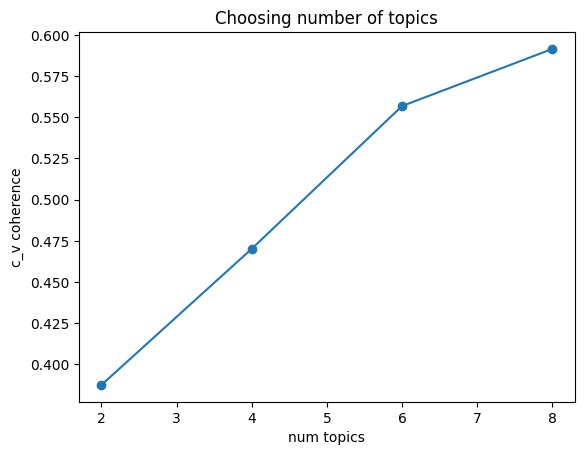

In [6]:
cm = CoherenceModel(model=lda, texts=tokens, dictionary=dictionary, coherence="c_v")
print("Coherence (c_v):", round(cm.get_coherence(), 4))

scores = {}
for k in [2, 4, 6, 8]:
    m = LdaModel(corpus, id2word=dictionary, num_topics=k, passes=5, random_state=42)
    scores[k] = CoherenceModel(model=m, texts=tokens, dictionary=dictionary, coherence="c_v").get_coherence()
plt.plot(list(scores), list(scores.values()), "o-"); plt.xlabel("num topics"); plt.ylabel("c_v coherence")
plt.title("Choosing number of topics"); plt.show()

In [7]:
def topics_of(text):
    bow = dictionary.doc2bow(prep(text))
    return sorted(lda.get_document_topics(bow, minimum_probability=0.05), key=lambda x: -x[1])

for t in ["The rocket launch by NASA reached orbit around the earth",
          "The team scored a goal in the third period of the hockey game"]:
    print(t, "->", [(k, round(float(p), 2)) for k, p in topics_of(t)])

The rocket launch by NASA reached orbit around the earth -> [(1, 0.85), (2, 0.12)]
The team scored a goal in the third period of the hockey game -> [(1, 0.95)]
